In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.pickle_functions import pickle_file_exists, load_from_pickle
from src.label_processing import update_labels
from src.hyperparam_processing import get_hyperparam_from_json

2023-11-21 14:33:42.860949: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2023-11-21 14:33:42.860970: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [2]:
pickle_name_fold = "cmu_mosei"
label_type = "all"
predict_neutral_class = False
threshold_emo_present = [0]
ext_name = ""

### List of scores

In [3]:
train_list = load_from_pickle(pickle_name_fold + "_train", "raw_folds", "cmu_mosei")
y_train = train_list[1]
y_train_array = np.reshape(np.array(y_train), (-1,6))
df = pd.DataFrame(y_train_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])

In [4]:
def compute_unique(label, to_return):
    all_sc = list(df[label].unique())
    all_sc.sort()
    print(all_sc)
    
    if to_return:
        return all_sc

In [5]:
compute_unique('happiness', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.3333334, 1.6666666, 2.0, 2.1666667, 2.3333333, 2.6666667, 3.0]


In [6]:
compute_unique('sadness', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.1666666, 1.3333334, 1.5, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [7]:
compute_unique('anger', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [8]:
compute_unique('surprise', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [9]:
compute_unique('disgust', False)

[0.0, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [10]:
compute_unique('fear', False)

[0.0, 0.16666667, 0.33333334, 0.6666667, 1.0, 1.3333334, 1.6666666]


In [11]:
all_scores = compute_unique('sadness', True)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.1666666, 1.3333334, 1.5, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


### Load training, validation and test data

In [12]:
param_training, param_task = get_hyperparam_from_json("param_training_task")

In [13]:
train_list = load_from_pickle(pickle_name_fold + "_train", "raw_folds", "cmu_mosei")
valid_list = load_from_pickle(pickle_name_fold + "_valid", "raw_folds", "cmu_mosei")
test_list = load_from_pickle(pickle_name_fold + "_test",  "raw_folds", "cmu_mosei")

The following updates the training, validation and test folds to the suitable label type.

In [14]:
train_list, valid_list, test_list = update_labels(train_list, valid_list, test_list, 
                                                  param_task, all_scores)

In [15]:
y_train = train_list[1]
y_train_array = np.reshape(np.array(y_train), (-1,6))
y_train_array.shape

(16314, 6)

In [16]:
y_valid = valid_list[1]
y_valid_array = np.reshape(np.array(y_valid), (-1,6))
y_valid_array.shape

(1870, 6)

In [17]:
y_test = test_list[1]
y_test_array = np.reshape(np.array(y_test), (-1,6))
y_test_array.shape

(4652, 6)

### Training data statistics

In [18]:
df_train = pd.DataFrame(y_train_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
df_train

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.666667,0.0,0.0,0.0,0.666667
1,0.000000,0.000000,0.0,0.0,0.0,0.000000
2,0.666667,0.666667,0.0,0.0,0.0,0.333333
3,0.333333,0.333333,0.0,0.0,0.0,0.000000
4,0.666667,0.000000,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...
16309,0.000000,0.000000,0.0,0.0,0.0,0.000000
16310,0.000000,0.000000,0.0,0.0,0.0,0.000000
16311,1.000000,0.000000,0.0,0.0,0.0,0.000000
16312,0.333333,0.000000,0.0,0.0,0.0,0.000000


In [19]:
df_train.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,16314.000000,16314.000000,16314.000000,16314.000000,16314.000000,16314.000000
mean,0.487236,0.160986,0.157778,0.048843,0.124342,0.040497
std,0.640115,0.331295,0.367436,0.171970,0.327238,0.151937
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.666667


<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}, ylabel='Frequency'>

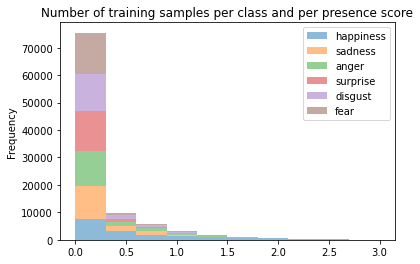

In [20]:
df_train.plot.hist(alpha=0.5, stacked=True,
            title="Number of training samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [21]:
count_train = []
for sc in all_scores:
    l = np.sum(y_train_array==sc, axis=0)
    count_train.append(l)
count_train_arr = np.array(count_train)
count_train_arr.shape

df_scores_train = pd.DataFrame(count_train_arr, 
                               columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                               index=all_scores)
df_scores_train

,happiness,sadness,anger,surprise,disgust,fear
0.000000,7587,12047,12791,14672,13360,14984
0.166667,18,7,1,2,0,8
0.333333,3055,2023,1398,1133,1343,816
0.500000,7,2,1,1,1,0
0.666667,1825,1416,935,355,824,372
0.833333,2,1,0,0,0,0
1.000000,1252,506,736,100,393,121
1.166667,0,1,0,0,0,0
1.333333,949,176,212,26,195,10
1.500000,0,1,0,0,0,0


<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}>

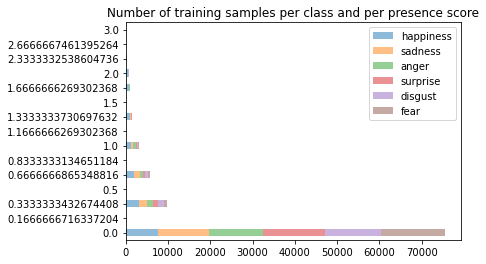

In [22]:
df_scores_train.plot.barh(alpha=0.5, stacked=True,
                          title="Number of training samples per class and per presence score")

<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}>

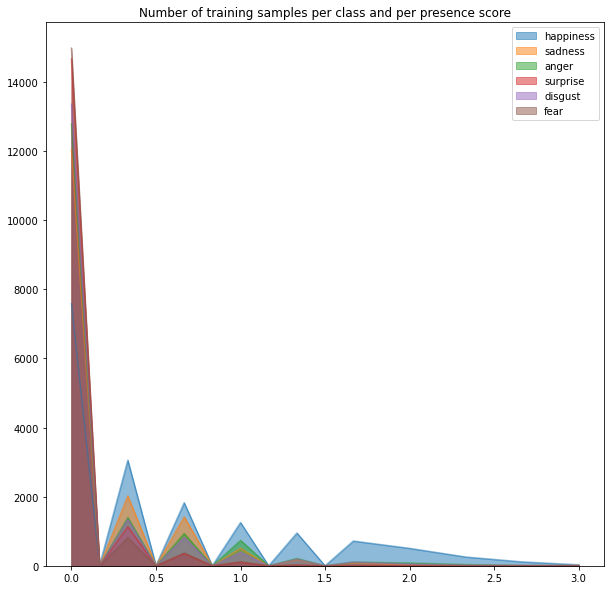

In [23]:
# df_scores_train.index.name = 'Presence score of the emotion'
df_scores_train.plot.area(stacked=False, figsize=(10,10), 
                          title="Number of training samples per class and per presence score")

### Validation data statistics

In [24]:
df_valid = pd.DataFrame(y_valid_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
df_valid

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.000000,0.0,0.0,0.000000,0.000000
1,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2,0.333333,0.333333,0.0,0.0,0.000000,0.000000
3,0.333333,0.000000,0.0,0.0,0.000000,0.000000
4,0.000000,0.333333,0.0,0.0,0.000000,0.000000
...,...,...,...,...,...,...
1865,0.000000,0.000000,0.0,0.0,0.000000,0.000000
1866,0.333333,0.000000,0.0,0.0,0.000000,0.000000
1867,0.333333,0.000000,0.0,0.0,0.000000,0.000000
1868,0.333333,0.000000,0.0,0.0,0.000000,0.333333


In [25]:
df_valid.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,1870.000000,1870.000000,1870.000000,1870.000000,1870.000000,1870.000000
mean,0.439037,0.167469,0.122103,0.050357,0.089840,0.044118
std,0.578941,0.326644,0.303954,0.165471,0.263077,0.153140
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,2.333333,1.666667,2.666667,1.000000


<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}, ylabel='Frequency'>

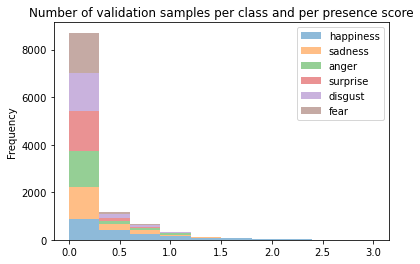

In [26]:
# df_valid.name = 'Presence score of the emotion'
df_valid.plot.hist(alpha=0.5, stacked=True,
            title="Number of validation samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [27]:
count_valid = []
for sc in all_scores:
    l = np.sum(y_valid_array==sc, axis=0)
    count_valid.append(l)
count_valid_arr = np.array(count_valid)
count_valid_arr.shape

df_scores_valid = pd.DataFrame(count_valid_arr, 
                               columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                               index=all_scores)
df_scores_valid

,happiness,sadness,anger,surprise,disgust,fear
0.000000,865,1350,1532,1667,1589,1694
0.166667,4,3,0,3,0,4
0.333333,402,243,133,139,152,115
0.500000,1,0,0,1,0,1
0.666667,220,181,107,47,76,39
0.833333,4,0,0,0,0,0
1.000000,141,62,72,7,34,17
1.166667,3,0,0,1,0,0
1.333333,84,19,15,3,8,0
1.500000,0,0,0,0,0,0


<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}>

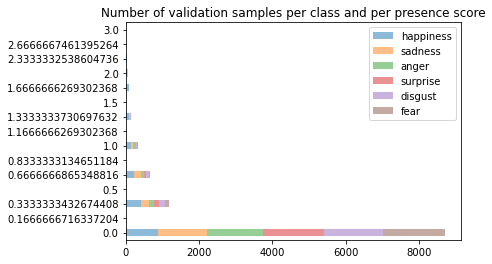

In [28]:
df_scores_valid.plot.barh(alpha=0.5, stacked=True,
                          title="Number of validation samples per class and per presence score")

<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}>

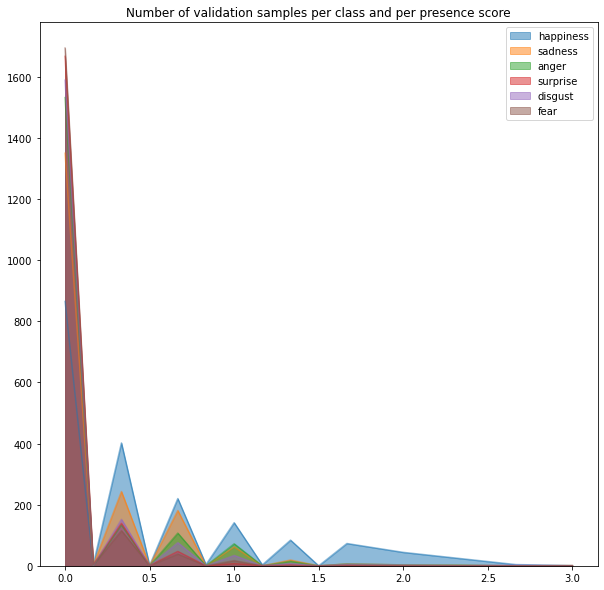

In [29]:
# df_scores_valid.index.name = 'Presence score of the emotion'
df_scores_valid.plot.area(stacked=False, figsize=(10,10), 
                         title="Number of validation samples per class and per presence score")

### Test data statistics

In [30]:
df_test = pd.DataFrame(y_test_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
df_test

,happiness,sadness,anger,surprise,disgust,fear
0,0.000000,0.333333,0.333333,0.0,0.0,0.000000
1,0.000000,0.333333,0.000000,0.0,0.0,0.000000
2,0.000000,0.333333,0.000000,0.0,0.0,0.000000
3,1.333333,0.000000,0.000000,0.0,0.0,0.000000
4,1.000000,0.000000,0.000000,0.0,0.0,0.000000
...,...,...,...,...,...,...
4647,0.666667,0.000000,0.000000,0.0,0.0,0.333333
4648,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4649,0.333333,0.000000,0.000000,0.0,0.0,0.000000
4650,2.333333,0.000000,0.000000,0.0,0.0,0.000000


In [31]:
df_test.describe(include='all')

,happiness,sadness,anger,surprise,disgust,fear
count,4652.000000,4652.000000,4652.000000,4652.000000,4652.000000,4652.000000
mean,0.468974,0.144490,0.163442,0.044139,0.117405,0.042706
std,0.606296,0.302431,0.360717,0.155825,0.317153,0.156531
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.000000,0.000000,0.000000,0.000000,0.000000
max,3.000000,2.333333,3.000000,2.333333,3.000000,1.333333


<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}, ylabel='Frequency'>

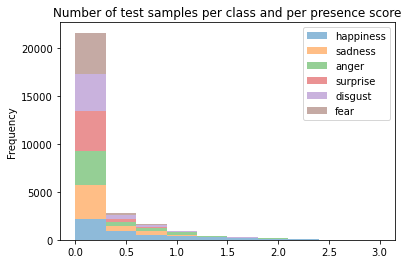

In [32]:
# df_test.name = 'Presence score of the emotion'
df_test.plot.hist(alpha=0.5, stacked=True,
            title="Number of test samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [33]:
count_test = []
for sc in all_scores:
    l = np.sum(y_test_array==sc, axis=0)
    count_test.append(l)
count_test_arr = np.array(count_test)
count_test_arr.shape

df_scores_test = pd.DataFrame(count_test_arr, 
                               columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                               index=all_scores)
df_scores_test

,happiness,sadness,anger,surprise,disgust,fear
0.000000,2154,3524,3582,4211,3847,4267
0.166667,1,2,0,0,0,0
0.333333,890,548,411,315,381,213
0.500000,1,1,0,0,1,0
0.666667,549,356,319,88,196,136
0.833333,0,0,0,0,0,0
1.000000,379,164,226,30,130,33
1.166667,0,0,0,0,0,0
1.333333,282,36,63,7,49,3
1.500000,0,0,0,0,0,0


<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}>

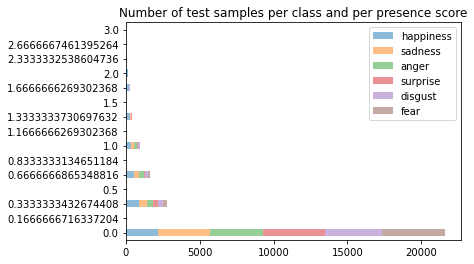

In [34]:
df_scores_test.plot.barh(alpha=0.5, stacked=True, 
                         title="Number of test samples per class and per presence score")

<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}>

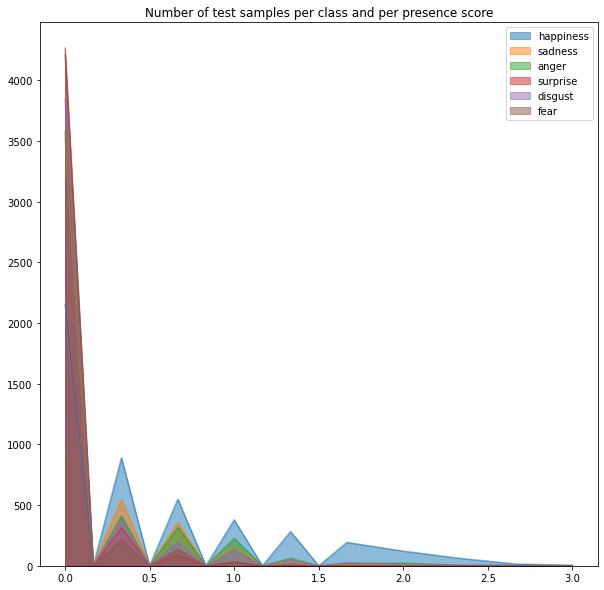

In [35]:
# df_scores_test.index.name = 'Presence score of the emotion'
df_scores_test.plot.area(stacked=False, figsize=(10,10), 
                         title="Number of test samples per class and per presence score")

# Diagram generation

Text(0.5, -0.2, 'Test')

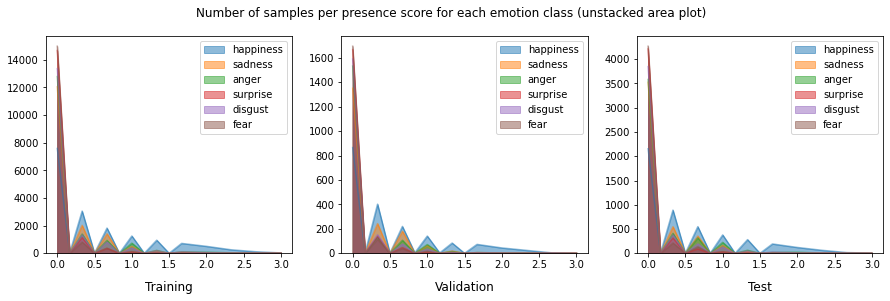

In [36]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Number of samples per presence score for each emotion class (unstacked area plot)')
df_scores_train.plot.area(ax=ax1, stacked=False, figsize=(15,4))
ax1.set_title("Training", y=-0.2)
df_scores_valid.plot.area(ax=ax2, stacked=False, figsize=(15,4))
ax2.set_title("Validation", y=-0.2)
df_scores_test.plot.area(ax=ax3, stacked=False, figsize=(15,4))
ax3.set_title("Test", y=-0.2)

Text(0, 0.5, '')

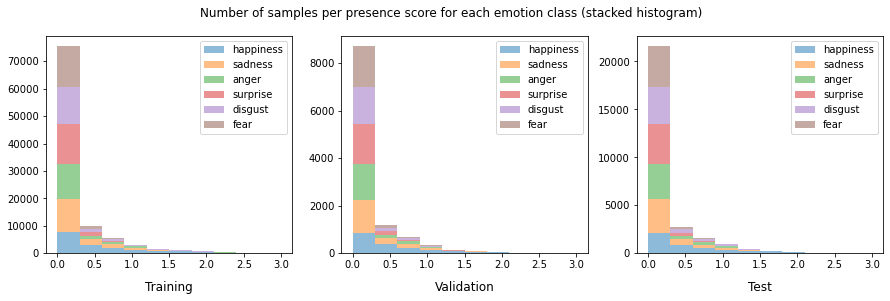

In [37]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Number of samples per presence score for each emotion class (stacked histogram)')
df_train.plot.hist(ax=ax1, alpha=0.5, stacked=True, figsize=(15,4), ylabel="")
ax1.set_title("Training", y=-0.2)
ax1.yaxis.set_label_text('') 
df_valid.plot.hist(ax=ax2, alpha=0.5, stacked=True, figsize=(15,4), ylabel="")
ax2.set_title("Validation", y=-0.2)
ax2.yaxis.set_label_text('') 
df_test.plot.hist(ax=ax3, alpha=0.5, stacked=True, figsize=(15,4), ylabel="")
ax3.set_title("Test", y=-0.2)
ax3.yaxis.set_label_text('') 